# NN_L6_top_words

**The words with the largest positive and negative difference between the positive and negative coefficients of a bag-of-words logistic regression on the Financial PhraseBank.**

Neural Networks and Deep Learning (NN), Lecture 6 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L6/NN_L6_top_words/NN_L6_top_words.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

$\beta_{positive}-\beta_{negative}$ per word: a sentiment dictionary learned from finance text.

most positive words = rose, increase, grew, up, improved   [words.pos]
most negative words = decreased, down, fell, cut, dropped   [words.neg]


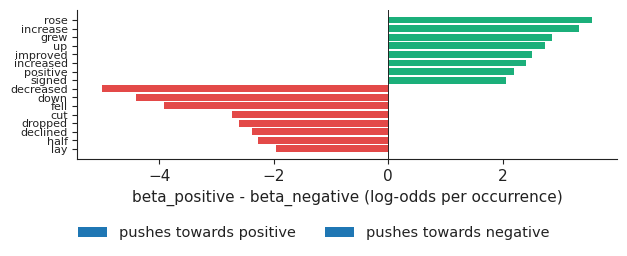

In [3]:
import json, urllib.request
_F = 'top_words_results.json'
R = json.load(open(_F)) if os.path.isfile(_F) else json.load(urllib.request.urlopen(REPO + 'Quantlets/L6/NN_L6_top_words/' + _F))
w = np.array(R['words']); d = np.array(R['diff']); pos = np.argsort(-d)[:8]; neg = np.argsort(d)[:8]
show('words.pos', 'most positive words', ', '.join(w[pos[:5]])); show('words.neg', 'most negative words', ', '.join(w[neg[:5]]))
fig, ax = plt.subplots(figsize=(6.4, 2.6)); v = np.concatenate([d[neg][::-1], d[pos][::-1]]); lab = list(w[neg][::-1]) + list(w[pos][::-1])
ax.barh(range(16), v, color=[PAL['positive']] * 8 + [PAL['benchmark']] * 8); ax.set_yticks(range(16)); ax.set_yticklabels(lab, fontsize=8); ax.axvline(0, color='#222222', lw=.7)
ax.set_xlabel('beta_positive - beta_negative (log-odds per occurrence)'); ax.barh([], [], color=PAL['benchmark'], label='pushes towards positive'); ax.barh([], [], color=PAL['positive'], label='pushes towards negative')
legend_bottom(fig, ncol=2); fig.tight_layout(rect=(0, .12, 1, 1))
fig.savefig('top_words.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()